# GEFS v12 → differentiable HBV → ensemble CRPS / CRPSS

Refactored from your uploaded `dhbv_1_1p_zn_plot.ipynb` and `tempfunctions.py`.

**Files in the same folder:** `gefs_crpss.py` handles daily `.npz` storage, date alignment, scoring, CSV output, and plots; `tempfunctions.py` retains the HBV model/restart and GEFS bias-correction helpers. No CRPS calculations are duplicated in `tempfunctions.py`.

**Dimensions:**

| Variable | Shape | Meaning |
|---|---|---|
| Each stored `.npz` key `forecast` | `(M, L)` | GEFS members × forecast lead days |
| `forecasts` after loading | `(I, L, M)` | initialization dates × lead days × members |
| `target_flow` | `(I, L)` | observed flow for each case |
| `initial_flow` | `(I,)` | observed flow immediately before each initialization |
| `crps_cases` | `(I, L)` | one ensemble CRPS for each case |
| `CRPS_forecast`, `CRPSS_pf`, `CRPSS_ad` | `(L,)` | scores averaged over valid initialization dates |

`I` is the number of existing forecast `.npz` files, not necessarily 362. `L=10` and `M=5` in your current experiment. **GEFS Day 1 = initialization date** (`LEAD1_OFFSET=0`); persistence uses the preceding day.

**The forecast-generation cell is optional.** Set `RUN_FORECASTS=False` to calculate CRPSS directly from existing saved `.npz` files. The hydrological model will not be initialized or run in this mode.

## 1. Load configuration and observed discharge

The forecast model is initialized only in the optional generation cell. We still need the dataset loader to access reference streamflow observations.

In [13]:
import sys
from pathlib import Path
import json
import importlib
import numpy as np
import pandas as pd
import torch

sys.path.append("../../")  # Needed for src.dmg in your repository layout

from src.dmg.core.utils import (
    import_data_loader,
    print_config,
    print_dataset_info,
    set_randomseed,
)
from example import load_config

import tempfunctions
import gefs_crpss as gefs

importlib.reload(tempfunctions)
importlib.reload(gefs)

MODEL_TYPE = "d3"  # d3, d2, or static
CONFIG_PATH = tempfunctions.get_config_path(MODEL_TYPE)
config = load_config(CONFIG_PATH)
config["mode"] = "sim"

print_config(config)
set_randomseed(config["seed"])

data_loader_cls = import_data_loader(config["data_loader"])
data_loader = data_loader_cls(config, test_split=False, overwrite=False)
print_dataset_info(data_loader.dataset)


Current Configuration
  Experiment Mode:    sim                 
  Model 1:            Hbv_1_1p            
  Dynamic Params:     ['parBETA', 'parK0', 'parBETAET']

Data Loader
  Data Source:        camels_531          
  Simulation Range :  2009/10/01          2013/09/30          

Experiment Parameters
  Train Epochs:       100                 Batch Size:         100                 
  Start Epoch:        0                   Save Epoch:         5                   
  Loss Fn:            NseBatchLoss        
  Optimizer:          Adadelta            LR Scheduler:       None                

Machine
  Device:             cuda:0              
  Dtype:              torch.float32       


Dataset Inputs
Dataset key    Shape               Description
------------------------------------------------------------
x_phy          (1461, 531, 3)       # [time, basin, forcing_features]
c_phy          (531, 0)             # [basin, attr_features] (no physical attributes here)
x_nn           (1461

## 2. Experiment settings

All important settings are in **one cell**. `MODE` applies to both generation and evaluation. Choose `CLIMATOLOGY_YEARS` deliberately: `None` reproduces the old implementation's all-available-dates reference, which can include the evaluation period; choose only pre-2012 years (e.g., `[2010, 2011]`) to avoid test-period look-ahead. Changing this setting changes the climatology CRPSS.

In [48]:
# Forecast experiment and dataset conventions
START_DATE, END_DATE = "2012-01-01", "2012-12-31"
YEAR = 2012
PRE, WINDOW, POST = "scalar", 30, True
N_LEADS, N_ENSEMBLES, WARMUP = 10, 5, 365
LEAD1_OFFSET = 0       # GEFS Day 1 is the initialization date
MIN_VALID_CASES = 30 
CLIMATOLOGY_YEARS = None  # Original scores; or [2010, 2011] for pre-2012 climatology

MODE = "single"         # "single" or "multiple"
BASIN_SET = "camels_531" # "best_36", "camels_531", "all_loaded"

SINGLE_BASIN_ID = "01139000" # "01137500"
RUN_FORECASTS = True    # False: reuse .npz forecasts; do not run HBV
SKIP_EXISTING = True

gage_ids = np.load(config["observations"]["gage_info"], allow_pickle=True)
subset_file = config["observations"]["subset_path"]
with open(subset_file, "r") as f:
    raw_subset = f.read().strip()
gage_ids_subset = (
    json.loads(raw_subset) if raw_subset.startswith("[")
    else np.loadtxt(subset_file, dtype=int).reshape(-1).tolist()
)

obs_name = config["observations"]["name"]
if obs_name == "camels_671":
    loader_basin_pool = [int(b) for b in gage_ids]
elif obs_name == "camels_531":
    loader_basin_pool = [int(b) for b in gage_ids_subset]
else:
    raise ValueError(f"Unexpected CAMELS observations name: {obs_name}")

if MODE == "single":
    eval_basins = [int(SINGLE_BASIN_ID)]

elif MODE == "multiple":

    if BASIN_SET == "best_36":
        eval_basins = [
            int(b) for b in tempfunctions.selectbasins()
        ]

    elif BASIN_SET == "camels_531":
        eval_basins = [
            int(b) for b in gage_ids_subset
        ]

    elif BASIN_SET == "all_loaded":
        eval_basins = list(loader_basin_pool)

    else:
        raise ValueError(f"Unknown BASIN_SET: {BASIN_SET}")

else:
    raise ValueError(f"Unknown MODE: {MODE}")

missing = sorted(set(eval_basins).difference(loader_basin_pool))
if missing:
    raise ValueError(f"Basins not in data-loader ordering: {missing}")

save_root = gefs.forecast_root(config, START_DATE, END_DATE, PRE, WINDOW, POST)
print("Selected basins:", len(eval_basins))
print("Saved forecast folder:", save_root)
print("Forecast generation requested:", RUN_FORECASTS)

Selected basins: 1
Saved forecast folder: output/Hbv_1_1p/3dyn/parBETA_parK0_parBETAET/camels_531/sim_results/GEFS_1year_forecasts/2012-01-01_2012-12-31_pre-scalar_w30_post-True
Forecast generation requested: True


## 3. OPTIONAL: Generate and save daily NPZ forecasts

Set `RUN_FORECASTS=True` above and rerun this cell **only** to generate missing forecasts. Generation calls `tempfunctions.run_segment()` and `tempfunctions.run_warm_forecasts_restart()` for each date; `.npz` saving is performed by `gefs.save_forecast_npz()`. Existing `.npz` forecasts remain unchanged when `SKIP_EXISTING=True`.

**IMPORTANT:** The original `tempfunctions` GEFS restart callback assumes a bias correction (`PRE="scalar"` or `"cdf"`). This notebook uses `"scalar"`. Full model generation requires your repository, trained model checkpoint, GEFS NetCDF files, and HPC environment.

In [49]:
if RUN_FORECASTS:
    from src.dmg import ModelHandler

    model = ModelHandler(config, verbose=True)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    gefs_results, failed_basins = {}, {}

    for position, gage_id in enumerate(eval_basins, start=1):
        print(f"Basin {position}/{len(eval_basins)}: {gage_id:08d}")
        try:
            result = gefs.run_gefs_one_year(
                GAGE_ID=gage_id,
                model=model,
                data_loader=data_loader,
                config=config,
                basin_pool=loader_basin_pool,  # ORDER MUST MATCH data_loader
                startid_endid=tempfunctions.startid_endid,
                run_segment=tempfunctions.run_segment,
                run_warm_forecasts_restart=tempfunctions.run_warm_forecasts_restart,
                post_processing=tempfunctions.post_processing,
                START_DATE=START_DATE, END_DATE=END_DATE,
                FORECAST=N_LEADS, N_ENSEMBLES=N_ENSEMBLES, WARMUP=WARMUP,
                WINDOW=WINDOW, PRE=PRE, POST=POST,
                device=device, skip_existing=SKIP_EXISTING,
            )
            gefs_results[gage_id] = result
            if result["n_failed"]:
                failed_basins[gage_id] = result["failed_dates"]
        except Exception as exc:
            failed_basins[gage_id] = str(exc)
            print(f"FAILED {gage_id:08d}: {exc}")

    gefs.print_gefs_summary(eval_basins, gefs_results, failed_basins)
else:
    print("Skipped HBV forecast generation; existing NPZ files will be used.")

Basin 1/1: 01139000
GEFS forecast for basin 01139000; 366 initializations; output: output/Hbv_1_1p/3dyn/parBETA_parK0_parBETAET/camels_531/sim_results/GEFS_1year_forecasts/2012-01-01_2012-12-31_pre-scalar_w30_post-True/01139000
FAILED 2012-05-09: Missing GEFS nc file: /beegfs/sets/aw-ciroh/common/met_fcsts/gefs_v12/camels_gII/camels671/zn_processed_hcst/gefs_processed_ens01/gefs_processed.2012050900.ens01.nc
FAILED 2012-05-27: Missing GEFS nc file: /beegfs/sets/aw-ciroh/common/met_fcsts/gefs_v12/camels_gII/camels671/zn_processed_hcst/gefs_processed_ens01/gefs_processed.2012052700.ens01.nc
FAILED 2012-10-15: Missing GEFS nc file: /beegfs/sets/aw-ciroh/common/met_fcsts/gefs_v12/camels_gII/camels671/zn_processed_hcst/gefs_processed_ens01/gefs_processed.2012101500.ens01.nc
FAILED 2012-12-31: Missing GEFS nc file: /beegfs/sets/aw-ciroh/common/met_fcsts/gefs_v12/camels_gII/camels671/zn_processed_hcst/gefs_processed_ens01/gefs_processed.2012123100.ens01.nc
Saved 362; skipped 0; failed 4

====

## 4. Build observed reference series and calculate CRPSS

`build_observed_basin_results()` extracts observed discharge after warmup and aligns the date axis to `config["sim_time"]`. Then `run_gefs_crpss()` loads **existing NPZ files** for each basin and calculates the exact kernel CRPS, persistence CRPS, and climatological-reference CRPS separately for each lead time.

In [50]:
basin_results = gefs.build_observed_basin_results(
    data_loader=data_loader,
    config=config,
    loader_basin_pool=loader_basin_pool,
    selected_basins=eval_basins,
    WARMUP=WARMUP,
)

In [51]:
import numpy as np
import pandas as pd
import torch
from pathlib import Path

from src.dmg import ModelHandler
import tempfunctions

# --------------------------------------------
# Settings
# --------------------------------------------
RUN_CONTINUOUS_SIM = True

# Include a model/checkpoint identifier in this directory
# when working with multiple calibrated models.
SIM_DIR = (
    Path(config["sim_dir"])
    / "continuous_daymet_reference"
)

SIM_DIR.mkdir(parents=True, exist_ok=True)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Construct/load the trained model only if needed.
# IMPORTANT: verify ModelHandler loads your calibrated checkpoint.
reference_model = None

# --------------------------------------------
# Only selected basins
# --------------------------------------------
for gage_id in eval_basins:

    gage_id = int(gage_id)
    basin_key = f"{gage_id:08d}"

    basin_idx = loader_basin_pool.index(gage_id)

    save_path = SIM_DIR / f"reference_{basin_key}.npz"

    expected_dates = pd.DatetimeIndex(
        basin_results[basin_key]["dates"]
    ).normalize()

    # ----------------------------------------
    # Option A: Load existing simulation
    # ----------------------------------------
    if save_path.exists():

        with np.load(save_path, allow_pickle=True) as data:
            qsim = np.asarray(data["sim"], dtype=float)
            saved_dates = pd.DatetimeIndex(
                pd.to_datetime(data["dates"])
            ).normalize()

            if "basin_id" in data:
                assert str(data["basin_id"].item()) == basin_key

        if not saved_dates.equals(expected_dates):
            raise ValueError(
                f"{basin_key}: cached dates do not match"
            )

        print(f"Loaded existing simulation: {basin_key}")

    # ----------------------------------------
    # Option B: Generate a new simulation
    # ----------------------------------------
    elif RUN_CONTINUOUS_SIM:

        if reference_model is None:
            reference_model = ModelHandler(
                config, verbose=True
            )
            reference_model.eval()

        qsim = tempfunctions.run_segment(
            model=reference_model,
            dataset=data_loader.dataset,
            basin_idx=basin_idx,
            device=device,
            start_idx=None,
            end_idx=None,
            warm_up=WARMUP,
            cache_states=False,
            warm_up_states=True,
        )

        qsim = np.asarray(qsim, dtype=float).reshape(-1)

        n_expected = len(expected_dates)
        n_total = data_loader.dataset["target"].shape[0]

        # Only trim if the model includes warm-up outputs
        if len(qsim) == n_total:
            qsim = qsim[WARMUP:]

        if len(qsim) != n_expected:
            raise ValueError(
                f"{basin_key}: simulation has {len(qsim)} "
                f"days; expected {n_expected}"
            )

        np.savez_compressed(
            save_path,
            basin_id=basin_key,
            dates=expected_dates.strftime("%Y-%m-%d").to_numpy(),
            sim=qsim,
        )

        print(f"Saved new simulation: {basin_key}")

    else:
        raise FileNotFoundError(
            f"Missing continuous simulation: {save_path}"
        )

    # ----------------------------------------
    # Attach qsim to CRPSS input
    # ----------------------------------------
    if qsim.shape != (len(expected_dates),):
        raise ValueError(f"Invalid simulation shape: {qsim.shape}")

    basin_results[basin_key]["sim"] = qsim

    print(
        f"{basin_key} | "
        f"Basin index: {basin_idx} | "
        f"Dates: {expected_dates[0].date()} to "
        f"{expected_dates[-1].date()} | "
        f"Qsim: {qsim.shape}"
    )

Saved new simulation: 01139000
01139000 | Basin index: 12 | Dates: 2010-10-01 to 2013-09-30 | Qsim: (1096,)


[1/1] 01139000: 362 forecasts


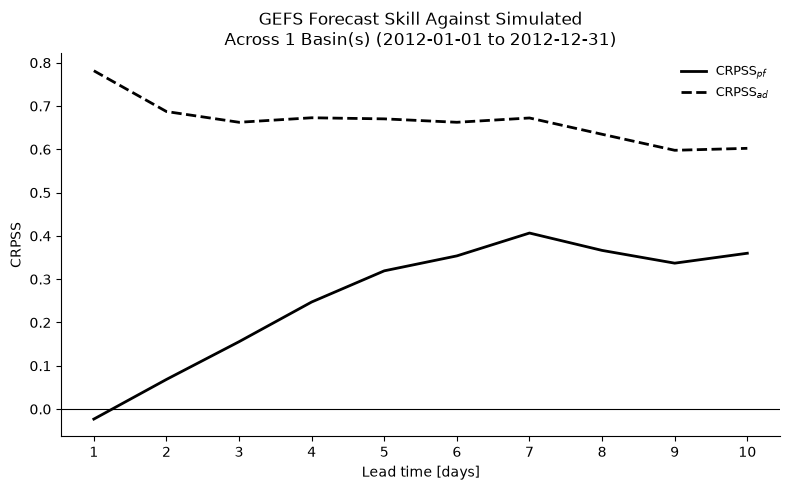

Evaluated: 1; failed: 0
Figure: output/Hbv_1_1p/3dyn/parBETA_parK0_parBETAET/camels_531/sim_results/GEFS_1year_forecasts/2012-01-01_2012-12-31_pre-scalar_w30_post-True/CRPSS_simulated_single/CRPSS_01139000_simulated_2012.png
CSV: output/Hbv_1_1p/3dyn/parBETA_parK0_parBETAET/camels_531/sim_results/GEFS_1year_forecasts/2012-01-01_2012-12-31_pre-scalar_w30_post-True/CRPSS_simulated_single/CRPSS_single_simulated_2012.csv


,basin_id,reference,lead_time,CRPSS_pf,CRPSS_ad,CRPS_forecast,CRPS_ref_pf,CRPS_ref_ad,n_valid
0,01139000,simulated,1,-0.023110,0.781487,0.259745,0.253878,1.188693,362
1,01139000,simulated,2,0.068472,0.687303,0.371700,0.399022,1.188693,362
2,01139000,simulated,3,0.155655,0.662474,0.401214,0.475178,1.188693,362
3,01139000,simulated,4,0.247344,0.672893,0.388829,0.516610,1.188693,362
4,01139000,simulated,5,0.319338,0.670353,0.391849,0.575688,1.188693,362
5,01139000,simulated,6,0.353864,0.662476,0.401212,0.620940,1.188693,362
6,01139000,simulated,7,0.406625,0.672420,0.389392,0.656233,1.188693,362
7,01139000,simulated,8,0.366488,0.634786,0.434127,0.685270,1.188693,362
8,01139000,simulated,9,0.337051,0.597783,0.478113,0.721191,1.188693,362
9,01139000,simulated,10,0.359970,0.602309,0.472732,0.738609,1.188693,362


Figure: output/Hbv_1_1p/3dyn/parBETA_parK0_parBETAET/camels_531/sim_results/GEFS_1year_forecasts/2012-01-01_2012-12-31_pre-scalar_w30_post-True/CRPSS_simulated_single/CRPSS_01139000_simulated_2012.png
CSV: output/Hbv_1_1p/3dyn/parBETA_parK0_parBETAET/camels_531/sim_results/GEFS_1year_forecasts/2012-01-01_2012-12-31_pre-scalar_w30_post-True/CRPSS_simulated_single/CRPSS_single_simulated_2012.csv
Failed basins: []


In [53]:
crpss_results = gefs.run_gefs_crpss(
    mode=MODE,
    config=config,
    basin_results=basin_results,
    basin_pool=eval_basins,
    GAGE_ID=eval_basins[0] if MODE == "single" else None,
    START_DATE=START_DATE, END_DATE=END_DATE,
    PRE=PRE, WINDOW=WINDOW, POST=POST,
    YEAR=YEAR, N_LEADS=N_LEADS, N_ENSEMBLES=N_ENSEMBLES,
    LEAD1_OFFSET=LEAD1_OFFSET,
    MIN_VALID_CASES=MIN_VALID_CASES, 
    CLIMATOLOGY_YEARS=CLIMATOLOGY_YEARS,
    show_plot=True,
)

display(crpss_results["results_df"])
print("Figure:", crpss_results["figure_path"])
print("CSV:", crpss_results["csv_path"])
print("Failed basins:", crpss_results["failed_basins"])

## 5. Reuse ONE loaded forecast array for diagnostics and other metrics

This cell loads one selected basin once, then subsequent cells reuse `forecasts`, `init_dates`, and `target_flow`. This avoids the extra metric loader/alias that duplicated file reads. See `crps_cases` for the CRPS of each initialization date and lead.

In [54]:
DIAG_BASIN_ID = int(eval_basins[0])  # Select basin for detailed diagnostics

forecasts, init_dates = gefs.load_basin_forecasts(
    save_root, DIAG_BASIN_ID,
    year=YEAR, start_date=START_DATE, end_date=END_DATE,
    n_members=N_ENSEMBLES, n_leads=N_LEADS,
)
qref = gefs.reference_series(basin_results, DIAG_BASIN_ID, REFERENCE)
target_flow, initial_flow = gefs.align_reference(
    qref, init_dates, N_LEADS, LEAD1_OFFSET
)
valid = gefs.valid_forecast_cases(forecasts, target_flow, initial_flow)
crps_cases = gefs.ensemble_crps_cases(forecasts, target_flow)
ensemble_mean = np.mean(forecasts, axis=2)

print("forecasts:", forecasts.shape, "(I,L,M)")
print("init_dates:", init_dates.shape, "(I,)")
print("target_flow:", target_flow.shape, "(I,L)")
print("initial_flow:", initial_flow.shape, "(I,)")
print("crps_cases:", crps_cases.shape, "(I,L)")
print("valid by lead:", valid.sum(axis=0))
print("Direct single-case CRPS check:", gefs.crps_single(forecasts[0, 0, :], target_flow[0, 0]))
print("Array CRPS at same position:", crps_cases[0, 0])

forecasts: (362, 10, 5) (I,L,M)
init_dates: (362,) (I,)
target_flow: (362, 10) (I,L)
initial_flow: (362,) (I,)
crps_cases: (362, 10) (I,L)
valid by lead: [362 362 362 362 362 362 362 362 362 362]
Direct single-case CRPS check: 0.019396543502807617
Array CRPS at same position: 0.019396543502807617


## 6. Additional deterministic scores for this basin

Calculate Nash–Sutcliffe efficiency (`NS`), Alfieri-sign percentage bias (`Pbias`, positive = underprediction), and RMSE / mean observed discharge (`CV`), using the same already-loaded `ensemble_mean` and `target_flow`. These are scores of the **ensemble mean**, not probabilistic CRPS.

,lead_time,NS,Pbias_pct,CV
0,1,0.740319,-1.013624,0.424255
1,2,0.202925,-2.524644,0.744638
2,3,0.027367,-5.217430,0.827104
3,4,-0.003802,-5.631881,0.832700
4,5,0.200406,-3.236210,0.753181
5,6,0.134245,-5.929146,0.788078
6,7,0.273064,-6.347297,0.722435
7,8,-0.619294,-18.423985,1.074670
8,9,-1.284194,-22.498817,1.279365
9,10,-0.412861,-18.019387,1.008882


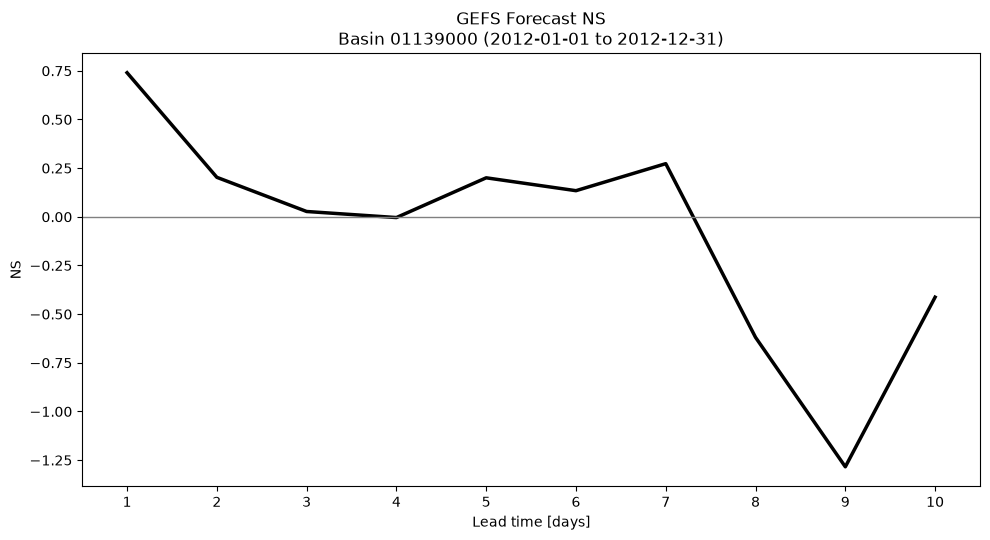

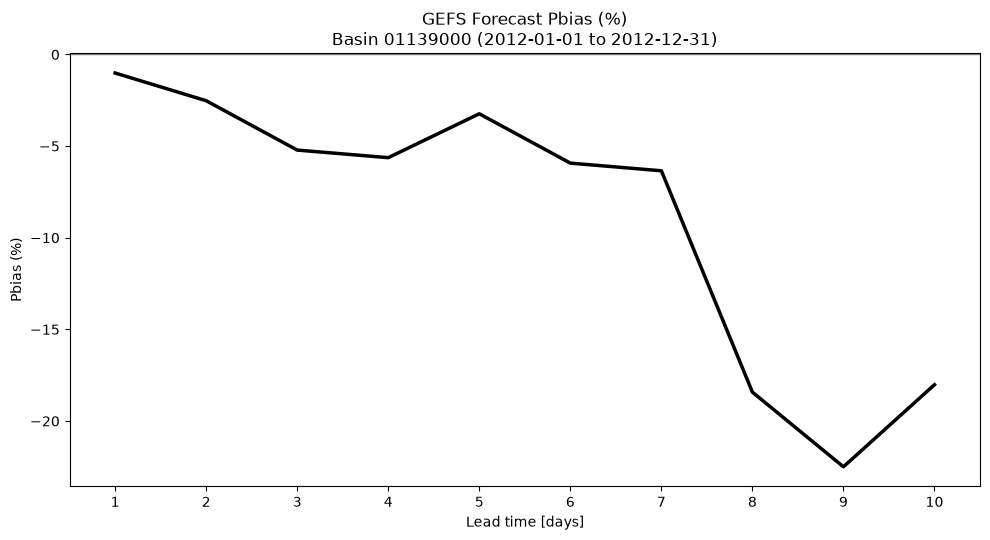

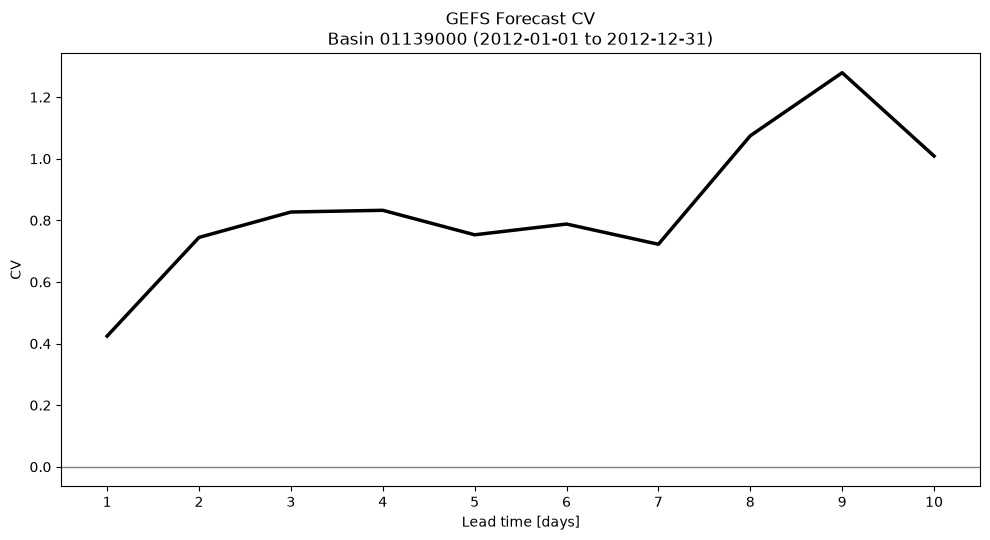

Metrics saved under: output/Hbv_1_1p/3dyn/parBETA_parK0_parBETAET/camels_531/sim_results/GEFS_1year_forecasts/2012-01-01_2012-12-31_pre-scalar_w30_post-True/Evaluation_plots/01139000


In [56]:
ns = gefs.calculate_gefs_ns(ensemble_mean, target_flow, MIN_VALID_CASES)
pbias = gefs.calculate_gefs_pbias(ensemble_mean, target_flow, MIN_VALID_CASES)
cv = gefs.calculate_gefs_cv(ensemble_mean, target_flow, MIN_VALID_CASES)

metric_df = pd.DataFrame({
    "lead_time": np.arange(1, N_LEADS + 1),
    "NS": ns,
    "Pbias_pct": pbias,
    "CV": cv,
})
display(metric_df)

plot_dir = save_root / "Evaluation_plots" / f"{DIAG_BASIN_ID:08d}"
for values, metric_name in [(ns, "NS"), (pbias, "Pbias (%)"), (cv, "CV")]:
    gefs.plot_gefs_metric(
        values, metric_name, save_dir=plot_dir,
        START_DATE=START_DATE, END_DATE=END_DATE, basin_id=DIAG_BASIN_ID,
    )
print("Metrics saved under:", plot_dir)